In [4]:
%matplotlib inline
import numpy as np
import scipy as sp
from scipy import linalg
from scipy import interpolate
from scipy import integrate
from scipy import special
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import itertools as itertools

# Gauss-Hermite collocation method

T. Tang, ``The Hermite Spectral Method for Gaussian-Type Functions'', SIAM J. Sci. Comput., Vol. 14, No. 3, 1993

The orthogonal basis functions are
\begin{equation}
    \psi_n(x) = \frac{1}{\sqrt{2^n n !}} H_n(x) e^{-x^2/2},
\end{equation}
where $H_n$ are the physicist's Hermite Polynomials and we have
\begin{equation}
    \left\langle \psi_i, \ \psi_j \right\rangle = \int_{-\infty}^{\infty} \psi_i(x) \psi_j(x) \text{d}x = \frac{1}{2^n n!} \int_{-\infty}^{\infty} H_i(x) H_j(x) e^{-x^2} \text{d}x = \sqrt{\pi} \delta_{i,j}.
\end{equation}

In [5]:
# evaluate basis functions
def psi_fun(n, x):
    if n < 201: # direct calculation
        Hn = sp.special.eval_hermite(n, x)
        z = np.square(x) + n*np.log(2) + sp.special.gammaln(n+1)
        psi = Hn * np.exp(-z/2.0)
    else: # recursive calculation
        psi0 = np.sqrt(2/n)*x*psi_fun(n-1, x) 
        psi1 = np.sqrt((n-1)/n)*psi_fun(n-2, x)
        psi = psi0 - psi1
    return psi

## Gauss-Hermite interpolation and differentiation matrices

J. A. C. Weideman and S. C. Reddy, ``A MATLAB Differentiation Matrix Suite'', ACM Trans. Math. Softw., 2000

In [6]:
def herdif(N, order):
    D_mats = [_ for _ in range(order)]
    
    # define collocation points
    x_coll, _ = sp.special.roots_hermite(N)
    
    # define constants c using equation (5 in W&R)
    c = np.exp(-np.square(x_coll)/2.0)
    for j in range(N):
        for k in range(j):
            c[j] = c[j]*(x_coll[j] - x_coll[k])
        
        for k in range(j+1,N):
            c[j] = c[j]*(x_coll[j] - x_coll[k])
    
    C = np.zeros((N,N))
    for i in range(N):
        for j in range(N):
            C[i,j] = c[i] / c[j]
    
    # compute beta's using equation (18 in W&R)
    B = np.zeros((order, N))
    bn1 = np.zeros(N)
    b0 = np.ones(N)
    for l in range(order):
        B[l,:] = -x_coll*b0 - l*bn1
        bn1 = np.copy(b0)
        b0 = np.copy(B[l,:])
    
    # define matrix Z
    Z = np.zeros((N,N))
    for i in range(N):
        for j in range(i+1, N):
            Z[i,j] = 1.0/(x_coll[i] - x_coll[j])
            Z[j,i] = 1.0/(x_coll[j] - x_coll[i])
    
    # define matrix X
    X = np.zeros((N-1,N))
    for i in range(N-1):
        for j in range(i+1):
            X[i,j] = 1.0/(x_coll[j] - x_coll[i+1])
        
        for j in range(i+1, N):
            X[i,j] = 1.0/(x_coll[j] - x_coll[i])
    
    # main recursion described in Table II of W&R
    Y = np.ones((N-1,N))
    D = np.eye(N)
    for l in range(order):
        # recursion for diagonals
        Y = np.cumsum( np.vstack([ np.reshape(B[l,:], (1,-1)) ,\
                                   (l+1)* Y[:N-1,:]*X ]), axis=0 )
        
        # recursion for off-diagonals
        D_rep = np.reshape(np.diag(D), (-1,1)) * np.ones((N,N))
        D = (l+1) * Z * (C * D_rep - D)
        
        # correct the diagonal of D
        for i in range(N):
            D[i,i] = Y[N-1, i]
        
        D_mats[l] = D
    
    return x_coll, D_mats

def herterp(N, x):
    # construct interpolation matrix mapping
    # f at collocation points to its interpolated values at x
    # (works up to about N=200)
    
    # collocation points
    x_coll, _ = sp.special.roots_hermite(N)
    
    # evaluation of hermite polynomials
    HN_x = sp.special.eval_hermite(N, x)
    dHN_coll = - sp.special.eval_hermite(N+1, x_coll)
    
    # Interpolation matrix
    R = np.zeros((len(x), N))
    for i in range(len(x)):
        for j in range(N):
            if np.absolute(x[i] - x_coll[j]) > 1.0e-12:
                phi = HN_x[i] / (dHN_coll[j] * (x[i] - x_coll[j]))
                R[i,j] = phi * np.exp(-np.square(x[i])/2 + np.square(x_coll[j])/2)
            else:
                R[i,j] = 1.0
    
    return R

## Test differentiation matrices

Text(0.5, 0, 'x')

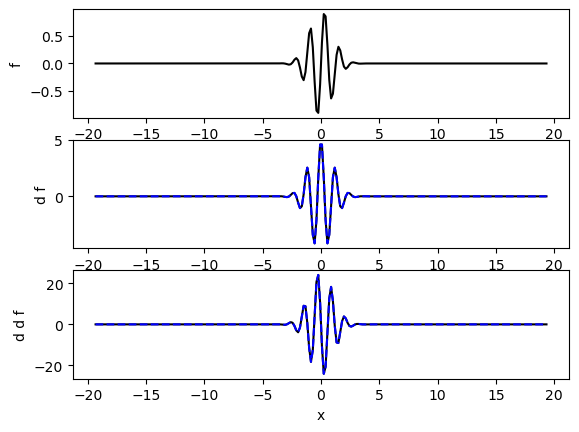

In [11]:
# a function and its derivatives
w = 5
f_test = lambda x: np.sin(w*x)*np.exp(-np.square(x)/2.0)
df_test = lambda x: w*np.cos(w*x)*np.exp(-np.square(x)/2.0) - np.sin(w*x)*x*np.exp(-np.square(x)/2.0)
d2f_test = lambda x: -np.square(w)*np.sin(w*x)*np.exp(-np.square(x)/2.0) - w*np.cos(w*x)*x*np.exp(-np.square(x)/2.0) \
                        - w*np.cos(w*x)*x*np.exp(-np.square(x)/2.0) - np.sin(w*x)*np.exp(-np.square(x)/2.0) \
                        + np.sin(w*x)*np.square(x)*np.exp(-np.square(x)/2.0)

# number of collocation points
N = 200

# collocation points and differentiation matrices
xi_coll, D_mats = herdif(N, 2)


# evaluate function at collocation points
f_coll = f_test(xi_coll)

# approximation of first derivative
df_coll = np.dot(D_mats[0], f_coll)

# approximation of second derivative
ddf_coll = np.dot(D_mats[1], f_coll)


fig = plt.figure()

ax = fig.add_subplot(3,1,1)
ax.plot(xi_coll, f_coll, color='k', linestyle='-', label='f')
ax.set_ylabel('f')

ax = fig.add_subplot(3,1,2)
ax.plot(xi_coll, df_test(xi_coll), color='k', linestyle='-', label='df')
ax.plot(xi_coll, df_coll, color='b', linestyle='--', label='df approx.')
ax.set_ylabel('d f')

ax = fig.add_subplot(3,1,3)
ax.plot(xi_coll, d2f_test(xi_coll), color='k', linestyle='-', label='df')
ax.plot(xi_coll, ddf_coll, color='b', linestyle='--', label='df approx.')
ax.set_ylabel('d d f')
ax.set_xlabel('x')

## Test interpolation matrices

Text(0.5, 0, 'x')

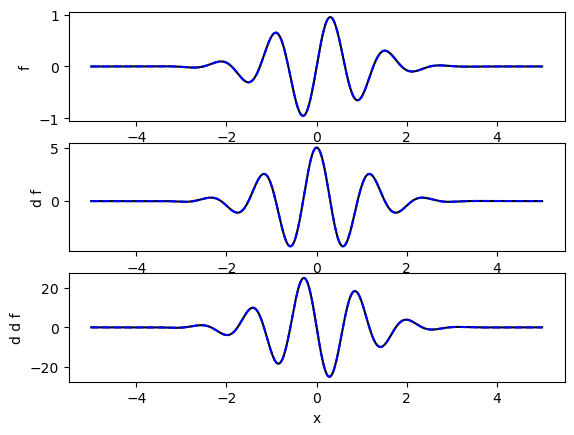

In [12]:
# interpolation points
xi_terp = np.linspace(-5, 5, 501)

# interpolation matrix
R_coll2terp = herterp(N, xi_terp)

# interpolate the function and its derivatives
f_terp = np.dot(R_coll2terp, f_coll)

df_terp = np.dot(R_coll2terp, df_coll)

ddf_terp = np.dot(R_coll2terp, ddf_coll)


fig = plt.figure()

ax = fig.add_subplot(3,1,1)
ax.plot(xi_terp, f_test(xi_terp), color='k', linestyle='-', label='f')
ax.plot(xi_terp, f_terp, color='b', linestyle='--', label='f approx.')
ax.set_ylabel('f')

ax = fig.add_subplot(3,1,2)
ax.plot(xi_terp, df_test(xi_terp), color='k', linestyle='-', label='df')
ax.plot(xi_terp, df_terp, color='b', linestyle='--', label='df approx.')
ax.set_ylabel('d f')

ax = fig.add_subplot(3,1,3)
ax.plot(xi_terp, d2f_test(xi_terp), color='k', linestyle='-', label='df')
ax.plot(xi_terp, ddf_terp, color='b', linestyle='--', label='df approx.')
ax.set_ylabel('d d f')
ax.set_xlabel('x')

# Complex Ginzburg-Landau Equation

\begin{equation}
    \frac{\partial q}{\partial t} = \left(- \nu \frac{\partial}{\partial x} + \gamma \frac{\partial^2}{\partial x^2} + \mu\right) q - a \vert q\vert^2 q + b u
\end{equation}

\begin{equation}
    \nu = U + 2 i c_u, \qquad \gamma = 1 + i c_d, \qquad \mu(x) = (\mu_0 - c_u^2) + \frac{1}{2} \mu_2 x^2
\end{equation}

See S. Bagheri, D. S. Henningson, J. Hoepffner, and P. J. Schmid, ''Input-Output Analysis and Control Design Applied to a Linear Model of Spatially Developing Flows'', Applied Mechanics Reviews, 2009.

Letting $\chi$ be a scaling factor so that $\chi x = \xi$, these equations become
\begin{equation}
    \frac{\partial q}{\partial t} = \left(- \nu \chi \frac{\partial}{\partial \xi} + \gamma \chi^2 \frac{\partial^2}{\partial \xi^2} + \mu\right) q - a \vert q\vert^2 q.
\end{equation}

We use the same scaling parameter value $\chi = \vert \mu_2 / (2\gamma)\vert^{1/4}$ as in S. Bagheri et al..
While the term stated in S. Bagheri has a typo, this parameter can be found in J.-M. Chomaz, ''Global Instabilities in Spatially Developing Flows: Non-Normality and Nonlinearity'', Annual Review of Fluid Mechanics, 2005.

The nonlinearity in the CGL equation is not analytic, making it impossible to compute complex Jacobians and gradients about any point besides the origin.
Therefore, we work with real variables $q = q_r + i q_i$, yielding the real system
\begin{equation}
\begin{aligned}
    \frac{\partial q_r}{\partial t} &= \left( -U \chi \frac{\partial}{\partial \xi} + \chi^2 \frac{\partial^2}{\partial \xi^2} + \mu \right) q_r + \left( 2 c_u \chi \frac{\partial}{\partial \xi} - c_d \chi^2 \frac{\partial^2}{\partial \xi^2} \right) q_i - a \left( q_r^2 + q_i^2 \right) q_r + b_r u_r - b_i u_i \\
    \frac{\partial q_i}{\partial t} &= \left( -2 c_u \chi \frac{\partial}{\partial \xi} + c_d \chi^2 \frac{\partial^2}{\partial \xi^2} \right) q_r + \left( -U \chi \frac{\partial}{\partial \xi} + \chi^2 \frac{\partial^2}{\partial \xi^2} + \mu \right) q_i - a \left( q_r^2 + q_i^2 \right) q_i + b_i u_r + b_r u_i.
\end{aligned}
\end{equation}

We use the complex-valued linear observation defined by
\begin{equation}
    y(q) = \int_{-\infty}^{\infty} \exp{\left[-\left(\frac{x - x_2}{s}\right)^2\right]} q(x) \text{d}x, \qquad s=1.6, \quad x_2 = \sqrt{-2(\mu_0 - c_u^2)/\mu_2}.
\end{equation}
This observation was used in M. Ilak, S. Bagheri, L. Brandt, C. W. Rowley, and D. S. Henningson, ''Model Reduction of the Nonlinear Complex Ginzburg-Landau Equation'', SIAM J. Applied Dynamical Systems, 2010.

Similarly, we have a complex-valued input $u(t)$ and
\begin{equation}
    b(x) = \exp{\left[-\left(\frac{x - x_1}{s}\right)^2\right]}, \qquad s=1.6, \quad x_1 = -\sqrt{-2(\mu_0 - c_u^2)/\mu_2}.
\end{equation}